# Agentic AI-Based Sales Lead Analysis and Follow-Up System Using RAG

A four-agent system that prioritises B2B sales leads and writes follow-up emails in which every product claim is checked against the company's own documentation before it goes out.

---

## 1. Problem statement

Sales teams lose time in two places: deciding **which leads to chase**, and writing follow-ups that are generic or, worse, **promise things the product cannot do**.

This notebook builds a multi-agent system that takes a CRM export of leads and, for each lead:

1. **scores and prioritises** it (Hot / Warm / Cold) with an explainable hybrid score,
2. **retrieves** the relevant product facts from a knowledge base (RAG) and picks the best-fit plan,
3. **drafts** a personalised follow-up email whose tone depends on the priority, and
4. **checks every product claim** in that email against the knowledge base, sending it back for revision until it is grounded.

**Objectives, each measured in Section 9**

| Objective | Measure |
|---|---|
| Prioritise leads the way a sales manager would | Accuracy against labels the agents never see, compared with a rules-only baseline |
| Retrieve the right product facts | Hit rate and MRR on a hand-written question set |
| Never send an email with made-up claims | Share of emails approved as grounded, first draft vs after the revision loop, plus an injected-hallucination test |

**Scenario.** *Brightlane Analytics* is a fictional business-intelligence SaaS company that sells dashboards to Indian SMBs. Its product knowledge base and the 12 leads below are synthetic and were written for this project.

## 2. System architecture

| # | Agent | What it decides | Tools / knowledge | Structured output |
|---|---|---|---|---|
| 1 | **Lead Analyst** | How promising the lead is | `rule_based_score` tool on CRM fields (0–60) + LLM reading of the notes for buying intent (0–40) | `IntentAssessment` |
| 2 | **Product Matcher** | Which plan fits, which features matter, what we *cannot* offer | `search_product_kb` tool (FAISS retrieval) | `ProductMatch` |
| 3 | **Follow-up Writer** | What to say, in a tone set by priority | Retrieved context + Reviewer feedback | `FollowUpEmail` |
| 4 | **Reviewer** | Whether every product claim is supported | Retrieved context only | `ReviewVerdict` |

**What makes it agentic (decisions taken at run time, not a fixed chain):**
- **Routing:** the Lead Analyst's priority decides the path. Cold leads skip the Product Matcher and get a short nurture email.
- **Self-correction:** the Reviewer sends rejected drafts back to the Writer with specific feedback, up to `MAX_REVISIONS = 2` times.
- **Escalation:** an email still ungrounded after two revisions is flagged for human review instead of being sent.

**Stack:** LangChain with LCEL chains (`prompt | llm.with_structured_output(Schema)`), Pydantic schemas, FAISS vector store, `all-MiniLM-L6-v2` sentence embeddings (run locally in Colab, free), and `gpt-oss-120b` served by Groq's free tier (Gemini can be switched in with one setting).

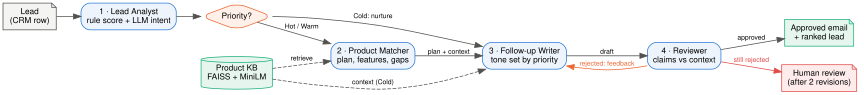

In [1]:
# Architecture diagram
try:
    import graphviz
    g = graphviz.Digraph(graph_attr={"rankdir": "LR", "nodesep": "0.35", "ranksep": "0.45", "fontname": "Helvetica", "size": "12,4"},
                         node_attr={"shape": "box", "style": "rounded,filled", "fontname": "Helvetica", "fontsize": "11",
                                    "fillcolor": "#eef4fc", "color": "#2a78d6"},
                         edge_attr={"fontname": "Helvetica", "fontsize": "9", "color": "#52514e"})
    g.node("lead", "Lead\n(CRM row)", shape="note", fillcolor="#f4f4f2", color="#52514e")
    g.node("a1", "1 · Lead Analyst\nrule score + LLM intent")
    g.node("route", "Priority?", shape="diamond", fillcolor="#fff1ea", color="#eb6834")
    g.node("a2", "2 · Product Matcher\nplan, features, gaps")
    g.node("kb", "Product KB\nFAISS + MiniLM", shape="cylinder", fillcolor="#e6f6ef", color="#1baf7a")
    g.node("a3", "3 · Follow-up Writer\ntone set by priority")
    g.node("a4", "4 · Reviewer\nclaims vs context")
    g.node("out", "Approved email\n+ ranked lead", shape="note", fillcolor="#e6f6ef", color="#1baf7a")
    g.node("human", "Human review\n(after 2 revisions)", shape="note", fillcolor="#fdeceb", color="#e34948")
    g.edge("lead", "a1"); g.edge("a1", "route")
    g.edge("route", "a2", label="Hot / Warm"); g.edge("route", "a3", label="Cold: nurture")
    g.edge("kb", "a2", label="retrieve", style="dashed"); g.edge("kb", "a3", label="context (Cold)", style="dashed")
    g.edge("a2", "a3", label="plan + context"); g.edge("a3", "a4", label="draft")
    g.edge("a4", "a3", label="rejected: feedback", color="#eb6834", fontcolor="#eb6834")
    g.edge("a4", "out", label="approved"); g.edge("a4", "human", label="still rejected", color="#e34948", fontcolor="#e34948")
    display(g)
except Exception as err:
    print(f"(graphviz unavailable: {err})")
    print("Lead -> [1 Lead Analyst] -> priority? --Hot/Warm--> [2 Product Matcher] -> [3 Writer] <-> [4 Reviewer] -> approved / human review")
    print("                                       --Cold-----> nurture context -----> [3 Writer]")

## 3. Setup

**Before running:**
1. Get a free Groq API key at [console.groq.com](https://console.groq.com) → *API Keys* (no card needed).
2. In Colab, open the **🔑 Secrets** panel in the left sidebar, add a secret named `GROQ_API_KEY`, and switch on *Notebook access*.
3. *Runtime → Run all.*

On Groq's free tier the first full run takes about 10 minutes, because the free tier allows only 8,000 tokens per minute and the client waits when it reaches that limit. Every agent response is saved in `agent_cache.json`, so later runs in the same session finish in seconds and give the same results. Delete that file to force fresh LLM calls.

In [2]:
# ---- Configuration ---------------------------------------------------------
PROVIDER = "groq"          # "groq" (recommended, free) or "gemini" (needs GOOGLE_API_KEY)
USE_CACHE = True           # re-use agent responses saved in agent_cache.json
HOT_AT, WARM_AT = 70, 45   # priority thresholds on the 0-100 lead score
MAX_REVISIONS = 2          # Reviewer -> Writer rounds before escalating to a human

In [3]:
llm_package = {"groq": "langchain-groq>=1.0,<2", "gemini": "langchain-google-genai>=4.0,<5"}[PROVIDER]
!pip install -q "langchain-core>=1.0,<2" "langchain-community>=0.4,<0.5" "langchain-text-splitters>=1.0,<2" "langchain-huggingface>=1.0,<2" "faiss-cpu>=1.8" "sentence-transformers>=3" graphviz "{llm_package}" > pip_log.txt 2>&1 && echo "Libraries installed" || tail -n 20 pip_log.txt

Libraries installed


In [4]:
import warnings
warnings.filterwarnings("ignore")

import hashlib, json, os, textwrap, time
from typing import Literal

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from pydantic import BaseModel, Field

from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.tools import tool
from langchain_text_splitters import MarkdownHeaderTextSplitter, RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_community.vectorstores.utils import DistanceStrategy

os.environ["TOKENIZERS_PARALLELISM"] = "false"
pd.set_option("display.max_colwidth", 90)
print("Imports OK")

Imports OK


In [5]:
def get_secret(name):
    """Read an API key from Colab Secrets; fall back to an environment variable, then a hidden prompt."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    from getpass import getpass
    return getpass(f"Enter {name}: ")


if PROVIDER == "groq":
    from langchain_groq import ChatGroq
    MODEL_ID = "openai/gpt-oss-120b"
    llm = ChatGroq(model=MODEL_ID, api_key=get_secret("GROQ_API_KEY"), temperature=0.2,
                   max_tokens=1024, max_retries=6, reasoning_effort="low")
elif PROVIDER == "gemini":
    from langchain_google_genai import ChatGoogleGenerativeAI
    MODEL_ID = "gemini-2.5-flash"
    llm = ChatGoogleGenerativeAI(model=MODEL_ID, api_key=get_secret("GOOGLE_API_KEY"), temperature=0.2,
                                 max_retries=6, thinking_budget=0)
else:
    raise ValueError("PROVIDER must be 'groq' or 'gemini'")

reply = llm.invoke("Reply with the single word: ready")
print(f"LLM connected: {PROVIDER} / {MODEL_ID} -> {reply.text.strip()}")

LLM connected: groq / openai/gpt-oss-120b -> ready


In [6]:
# Every agent call goes through here: cache lookup, retries with back-off, call counting.
CACHE_FILE = "agent_cache.json"
CACHE = json.load(open(CACHE_FILE)) if USE_CACHE and os.path.exists(CACHE_FILE) else {}
STATS = {"llm_calls": 0, "cache_hits": 0}


def call_agent(agent_name, chain, schema, inputs, max_attempts=4):
    key = hashlib.sha256(json.dumps([MODEL_ID, agent_name, inputs], sort_keys=True,
                                    ensure_ascii=False, default=str).encode()).hexdigest()
    if USE_CACHE and key in CACHE:
        STATS["cache_hits"] += 1
        return schema(**CACHE[key])
    for attempt in range(1, max_attempts + 1):
        try:
            result = chain.invoke(inputs)
            if result is None:
                raise ValueError("the model returned no structured output")
            break
        except Exception as err:
            text = str(err).lower()
            if "invalid api key" in text or "api_key_invalid" in text or "401" in text:
                raise  # a wrong key will not fix itself
            if attempt == max_attempts:
                raise
            wait = 15 * attempt
            print(f"   ... {agent_name}: {type(err).__name__}, retrying in {wait}s")
            time.sleep(wait)
    STATS["llm_calls"] += 1
    CACHE[key] = result.model_dump()
    if USE_CACHE:
        with open(CACHE_FILE, "w") as f:
            json.dump(CACHE, f)
    return result


print(f"Agent runner ready ({len(CACHE)} cached responses loaded)")

Agent runner ready (0 cached responses loaded)


## 4. Data

Two inputs, both written to files by the cells below so the notebook is self-contained:

- **`brightlane_kb.md`** – the product knowledge base the RAG pipeline searches: plans and prices, integrations, AI features, security, support, billing, what is *not* offered, case studies and an FAQ.
- **`leads.csv`** – 12 leads as a CRM would export them. The column `expected_priority` is the sales manager's own judgement. It is **removed before any agent sees the data** and used only to grade the system in Section 9.

In [7]:
%%writefile brightlane_kb.md
# Brightlane Analytics - Product Knowledge Base

## Company overview
Brightlane Analytics is a fictional company created for this project. It is a cloud business-intelligence (BI) platform built for Indian small and mid-sized businesses. Brightlane connects a company's sales, finance and marketing data in one place and turns it into live dashboards, AI forecasts and scheduled reports. Founded in 2021 and headquartered in Bengaluru, it serves over 1,200 businesses in retail, D2C e-commerce, healthcare, education, logistics and food & beverage.

## Plans and pricing
Brightlane has three plans: Starter, Growth and Enterprise. All prices are per month in Indian Rupees (INR) and exclude 18% GST. With annual billing you pay for 10 months and get 12.

### Starter plan
Price: Rs 4,999 (₹4,999) per month. For small teams getting started with dashboards.
- Up to 5 users
- 3 data connectors: Google Sheets, Excel/CSV upload and Shopify
- 20 pre-built dashboard templates (sales, inventory, marketing)
- Data refresh once a day
- Scheduled email reports (daily or weekly)
- 10 GB data storage
- Support: email only, response within 24 business hours
- Help-centre articles and video tutorials for self-onboarding

### Growth plan
Price: Rs 14,999 (₹14,999) per month. For growing businesses that need more data sources and AI features.
- Up to 25 users
- Up to 15 data connectors from the Growth catalogue (see Integrations), including Tally
- Hourly data refresh
- AI demand forecasting, Ask Brightlane (natural-language questions) and anomaly alerts
- Scheduled reports by email and WhatsApp
- 100 GB data storage
- Support: chat and email, response within 4 business hours
- 2 guided onboarding sessions (60 minutes each) with a product specialist

### Enterprise plan
Price: from Rs 49,999 (₹49,999) per month, custom quote. For multi-location and regulated businesses.
- Unlimited users and everything in Growth
- All connectors, plus custom API connectors built by the Brightlane team
- Data refresh every 15 minutes
- Single sign-on (SAML 2.0 with Okta, Azure AD or Google Workspace)
- Role-based access control, for example branch-level access
- Audit logs retained for 1 year
- Dedicated customer success manager
- 24/7 priority support with a 1-hour response for critical issues, including phone support
- 99.9% uptime SLA
- Optional private-cloud deployment in a dedicated AWS environment in the Mumbai region
- Full implementation programme, typically 4 to 6 weeks

## Integrations
- Starter: Google Sheets, Excel/CSV upload and Shopify only.
- Growth catalogue (choose up to 15): everything in Starter, plus Tally Prime, Zoho Books, Razorpay, Amazon Seller Central, Flipkart Seller Hub, Google Ads, Meta Ads, Google Analytics 4, PostgreSQL, MySQL, Microsoft SQL Server and HubSpot CRM.
- Enterprise: every connector above, plus custom API connectors (for example SAP or an in-house ERP) built by the Brightlane team.
- Tally and the database connectors (PostgreSQL, MySQL, SQL Server) are not available on the Starter plan.

## AI features
Available on the Growth and Enterprise plans.
- AI demand forecasting predicts product-level demand for the next 4 to 12 weeks from sales history, seasonality and Indian festival calendars (Diwali, Eid, Onam and others). It needs at least 6 months of sales history.
- Ask Brightlane: type a question such as "Which store had the highest sales last week?" in English or Hindi and get a chart in seconds.
- Anomaly alerts are sent by email or WhatsApp when sales, refunds or ad spend move unusually.

## Security and compliance
- ISO/IEC 27001:2022 certified.
- Data is encrypted at rest (AES-256) and in transit (TLS 1.2 or higher).
- All customer data is hosted in India, in the AWS Mumbai region (ap-south-1).
- Designed to support compliance with India's Digital Personal Data Protection (DPDP) Act, 2023; a data processing agreement is available on request.
- Brightlane is not HIPAA certified and does not hold a SOC 2 attestation.
- Daily encrypted backups are retained for 30 days.

## Support and onboarding
- Starter: email support (response within 24 business hours), help centre and video tutorials.
- Growth: chat and email support (response within 4 business hours) and 2 guided onboarding sessions.
- Enterprise: 24/7 priority support with phone support and a 1-hour response for critical issues, a dedicated customer success manager and a 4 to 6 week implementation.
- Support hours for Starter and Growth are Monday to Saturday, 9 am to 7 pm IST.

## Free trial, billing and discounts
- 14-day free trial of the Starter or Growth plan; no credit card required.
- Monthly plans can be cancelled at any time. Annual plans are refundable only within the first 30 days.
- Annual billing: pay for 10 months, get 12.
- Startup programme: 30% off the Growth plan for the first year for DPIIT-recognised startups that are less than 3 years old.
- Payment by UPI, credit or debit card, net banking or bank transfer, with GST invoices.
- There is no free-forever plan, and no other discounts are offered as standard.

## Not currently offered
- On-premise installation on the customer's own servers (Enterprise offers a private cloud on AWS instead).
- An iOS (iPhone) app; it is planned for 2027. An Android app and a mobile-friendly web app are available on all plans.
- Phone support on the Starter and Growth plans.
- HIPAA certification or a SOC 2 attestation.
- Custom connectors on the Starter or Growth plans.
- A free-forever plan.

## Case studies

### Case study: UrbanKart
UrbanKart, a D2C home-goods brand in Pune, is on the Growth plan. It connected Shopify, Razorpay and Meta Ads to Brightlane. Weekly reporting time fell from 10 hours to 1 hour, and AI demand forecasting reduced stockouts by 22% within 3 months, including during its Diwali sale.

### Case study: MedLine Diagnostics
MedLine Diagnostics, a chain of 14 diagnostic labs in Hyderabad, is on the Enterprise plan. It used single sign-on and branch-level role-based access to give each lab manager their own dashboard, built on billing data from PostgreSQL. With daily operations reviews on Brightlane, report-delivery delays fell by 30% in two quarters.

### Case study: Café Ritual
Café Ritual, a 3-outlet café chain in Bengaluru, is on the Starter plan. It replaced manual Excel consolidation with Google Sheets dashboards. The owner now checks outlet-wise sales on her phone each morning and saves about 6 hours a week.

## Frequently asked questions
**Does Brightlane work with Tally?** Yes. Tally Prime is supported on the Growth and Enterprise plans, not on Starter.

**Can reports be sent on WhatsApp?** Yes, on Growth and Enterprise. Starter sends scheduled reports by email only.

**How long does setup take?** Most Starter and Growth customers see their first dashboard on the same day they connect a data source. Enterprise implementation typically takes 4 to 6 weeks.

**Can we move from Starter to Growth later?** Yes. You can upgrade at any time and the price difference is pro-rated for the current billing period.

**Is there a mobile app?** An Android app and a mobile-friendly web app are available. An iOS app is planned for 2027.

**Which languages are supported?** The interface and Ask Brightlane support English and Hindi.

Writing brightlane_kb.md


In [8]:
%%writefile leads.csv
lead_id,contact_name,company,industry,employees,monthly_budget_inr,stated_need,source,days_since_contact,pricing_page_visits,demo_requested,email_opens,notes,expected_priority
L01,Priya Raman,Spice Route Foods,D2C packaged foods,85,18000,"One dashboard for Shopify, Amazon Seller Central and Razorpay sales, plus demand forecasting before the festive season",Website demo request,2,5,Yes,6,Head of Growth and the decision maker. Her team spends about 12 hours a week on Excel reports. Wants to start this month; comparing us with one other tool.,Hot
L02,Arjun Mehta,SwiftCart Logistics,Logistics,320,60000,"Branch-wise dashboards for 9 warehouses on PostgreSQL data, with single sign-on and role-based access",Trade show,5,3,Yes,4,VP Operations. IT security requires SSO and audit logs. Budget approved for this quarter; asked for an Enterprise quote and a security questionnaire.,Hot
L03,Dr. Sneha Kulkarni,CarePlus Clinics,Healthcare (clinic chain),140,20000,"Patient footfall and revenue dashboards across 6 clinics, using billing data from Tally and MySQL",Website demo request,4,2,Yes,2,Founder. Wants patient data hosted in India and asked whether we are HIPAA certified. Wants a pilot to start next week.,Hot
L04,Rohit Bansal,UrbanThreads,D2C fashion,45,15000,"Inventory and ad-spend dashboards from Shopify, Meta Ads and Google Ads, with stockout forecasting before the Diwali sale",Referral,24,0,No,0,"Co-founder, referred by UrbanKart's founder: 'we want exactly what UrbanKart has'. Verbally agreed to the Growth plan on the call, asked for the contract and onboarding dates, wants to go live within 3 weeks.",Hot
L05,Fatima Sheikh,BrightPath Academy,EdTech,60,8000,Track student enrolments and course revenue from Google Sheets and Razorpay,Webinar,14,2,No,4,Operations manager. Liked the webinar but needs approval from the director; plans to evaluate tools next quarter. Asked if annual billing is cheaper.,Warm
L06,Vikram Desai,Desai Hardware Mart,Retail (4 stores),35,6000,"Store-wise daily sales from Tally, with reports sent on WhatsApp",Google Ads landing page,18,1,No,1,"Owner. Interested but 'not urgent, maybe after Diwali'. Asked whether Tally works on the Starter plan.",Warm
L07,Ananya Iyer,GreenLeaf Organics,Organic food D2C,25,5000,Sales and marketing ROI dashboards from Shopify and Meta Ads,LinkedIn,35,3,Yes,2,"Marketing lead. Attended a demo last month, then went quiet; says budget is tight. They are a DPIIT-recognised startup, 2 years old, and might move ahead if there is a startup discount.",Warm
L08,Meera Joshi,Joshi Bakes & Cafe,Food & beverage (3 outlets),18,5000,A simple way to see outlet-wise sales on her phone instead of consolidating Excel sheets every night,Website contact form,100,0,No,3,Owner. Filled the contact form 3 months ago and was never followed up. Her message said she spends 2 hours every night consolidating outlet sales in Excel; asked about a free trial.,Warm
L09,Rahul Verma,Self-employed (student),Education (student),1,0,A free dashboard tool for a college project,Website contact form,3,2,No,1,Final-year student who needs a tool for a 2-week college assignment. No budget; asked if there is a free plan.,Cold
L10,Sanjay Gupta,Gupta Traders,Wholesale trading,8,1500,Not stated (imported from a purchased contact list),Purchased list,120,0,No,0,No reply to two cold emails. No requirement known.,Cold
L11,Karan Malhotra,Apex Fintech,Fintech,1200,50000,Researching BI tools for an internal comparison report,Webinar,40,2,No,2,"Analyst in the strategy team, not a decision maker. The company signed a 3-year Power BI enterprise contract last quarter; he said there are 'no plans to switch before 2028'.",Cold
L12,Neha Agarwal,Agarwal Jewellers,Retail (jewellery),12,3000,Basic sales reports,Trade show,60,1,No,2,Picked up a brochure at a trade show. Says they are happy with the reports in their current billing software; 'maybe next year'.,Cold

Writing leads.csv


In [9]:
leads_df = pd.read_csv("leads.csv")
labels = leads_df.set_index("lead_id")["expected_priority"]   # hidden ground truth, for evaluation only
leads = leads_df.drop(columns=["expected_priority"])           # what the agents see
LEADS = leads.to_dict("records")

print(f"{len(leads)} leads loaded; ground-truth labels held back: {labels.value_counts().to_dict()}")
display(leads[["lead_id", "contact_name", "company", "industry", "employees", "monthly_budget_inr",
               "source", "days_since_contact", "pricing_page_visits", "demo_requested", "email_opens"]])

12 leads loaded; ground-truth labels held back: {'Hot': 4, 'Warm': 4, 'Cold': 4}


,lead_id,contact_name,company,industry,employees,monthly_budget_inr,source,days_since_contact,pricing_page_visits,demo_requested,email_opens
0,L01,Priya Raman,Spice Route Foods,D2C packaged foods,85,18000,Website demo request,2,5,Yes,6
1,L02,Arjun Mehta,SwiftCart Logistics,Logistics,320,60000,Trade show,5,3,Yes,4
2,L03,Dr. Sneha Kulkarni,CarePlus Clinics,Healthcare (clinic chain),140,20000,Website demo request,4,2,Yes,2
3,L04,Rohit Bansal,UrbanThreads,D2C fashion,45,15000,Referral,24,0,No,0
4,L05,Fatima Sheikh,BrightPath Academy,EdTech,60,8000,Webinar,14,2,No,4
5,L06,Vikram Desai,Desai Hardware Mart,Retail (4 stores),35,6000,Google Ads landing page,18,1,No,1
6,L07,Ananya Iyer,GreenLeaf Organics,Organic food D2C,25,5000,LinkedIn,35,3,Yes,2
7,L08,Meera Joshi,Joshi Bakes & Cafe,Food & beverage (3 outlets),18,5000,Website contact form,100,0,No,3
8,L09,Rahul Verma,Self-employed (student),Education (student),1,0,Website contact form,3,2,No,1
9,L10,Sanjay Gupta,Gupta Traders,Wholesale trading,8,1500,Purchased list,120,0,No,0


## 5. RAG pipeline

1. **Chunk.** The knowledge base is split on its Markdown headings, so each chunk is one section (a plan, a case study, the security policy). Long sections are split further at about 900 characters. Each chunk keeps its section name, which the agents cite and Section 9 grades on.
2. **Embed.** `all-MiniLM-L6-v2` turns each chunk into a 384-dimensional vector. Vectors are normalised, so inner product equals cosine similarity.
3. **Index.** The vectors go into a **FAISS** inner-product index.
4. **Retrieve.** The `search_product_kb` tool returns the top-k chunks with their similarity scores.

In [10]:
kb_text = open("brightlane_kb.md", encoding="utf-8").read()
header_splitter = MarkdownHeaderTextSplitter([("#", "title"), ("##", "section"), ("###", "subsection")])
size_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=100)

chunks = []
for part in header_splitter.split_text(kb_text):
    section = part.metadata.get("subsection") or part.metadata.get("section") or "Overview"
    for piece in size_splitter.split_text(part.page_content):
        chunks.append(Document(page_content=f"[{section}]\n{piece}",
                               metadata={"section": section, "chunk_id": len(chunks)}))

print(f"{len(chunks)} chunks from {len({c.metadata['section'] for c in chunks})} sections")
display(pd.DataFrame([{"chunk": c.metadata["chunk_id"], "section": c.metadata["section"],
                       "characters": len(c.page_content)} for c in chunks]).set_index("chunk"))

15 chunks from 15 sections


,section,characters
chunk,,
0,Company overview,498
1,Plans and pricing,202
2,Starter plan,456
3,Growth plan,534
4,Enterprise plan,722
5,Integrations,557
6,AI features,511
7,Security and compliance,487
8,Support and onboarding,471


In [11]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2",
                                   encode_kwargs={"normalize_embeddings": True})
print("Embedding model loaded: all-MiniLM-L6-v2")

Embedding model loaded: all-MiniLM-L6-v2


In [12]:
vector_store = FAISS.from_documents(chunks, embeddings, distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT)
print(f"FAISS index built: {vector_store.index.ntotal} vectors of dimension {vector_store.index.d}")


@tool
def search_product_kb(query: str, k: int = 4) -> list:
    """Search the Brightlane product knowledge base; return the k most relevant chunks with cosine similarity."""
    hits = vector_store.similarity_search_with_score(query, k=k)
    return [{"chunk_id": d.metadata["chunk_id"], "section": d.metadata["section"],
             "score": round(float(s), 3), "text": d.page_content} for d, s in hits]


def format_context(hits):
    return "\n\n".join(f"({i}) {h['text']}" for i, h in enumerate(hits, 1))

FAISS index built: 15 vectors of dimension 384


In [13]:
# Retrieval test: does a lead's typical question bring back the right section?
for question in ["Can I connect Tally on the Starter plan?", "Is Brightlane HIPAA certified?"]:
    print(f"Q: {question}")
    for h in search_product_kb.invoke({"query": question, "k": 3}):
        print(f"   {h['score']:.3f}  [{h['section']}]  {h['text'].splitlines()[1][:85]}...")
    print()

Q: Can I connect Tally on the Starter plan?
   0.508  [Integrations]  - Starter: Google Sheets, Excel/CSV upload and Shopify only....
   0.404  [Frequently asked questions]  **Does Brightlane work with Tally?** Yes. Tally Prime is supported on the Growth and ...
   0.387  [Free trial, billing and discounts]  - 14-day free trial of the Starter or Growth plan; no credit card required....

Q: Is Brightlane HIPAA certified?
   0.567  [Security and compliance]  - ISO/IEC 27001:2022 certified....
   0.418  [Company overview]  Brightlane Analytics is a fictional company created for this project. It is a cloud b...
   0.388  [Case study: MedLine Diagnostics]  MedLine Diagnostics, a chain of 14 diagnostic labs in Hyderabad, is on the Enterprise...



## 6. The four agents

Each agent is an **LCEL chain**: a prompt template piped into the LLM, which is forced to answer in a Pydantic schema (`prompt | llm.with_structured_output(Schema)`). Structured outputs mean the orchestrator can make decisions on fields like `approved` or `intent_score` instead of parsing free text.

### 6.1 Agent 1 – Lead Analyst
The score is **hybrid**, so it can be both explained and defended:
- The **`rule_based_score` tool (0–60)** is deterministic, built from CRM fields: budget fit (20), company size (10), recency (15) and engagement (15).
- The **LLM intent score (0–40)** reads the stated need and the sales notes, which no rule can interpret: who the contact is, the timeline, whether they are locked into a competitor.

Total ≥ 70 → **Hot**, ≥ 45 → **Warm**, otherwise **Cold**.

In [14]:
@tool
def rule_based_score(monthly_budget_inr: float, employees: int, days_since_contact: int,
                     pricing_page_visits: int, demo_requested: str, email_opens: int) -> dict:
    """Deterministic lead score (0-60) from CRM fields: budget fit, company size, recency and engagement."""
    b = monthly_budget_inr
    budget = 20 if b >= 14999 else 12 if b >= 4999 else 5 if b >= 2500 else 0     # fits Growth / Starter / almost
    size = 10 if 10 <= employees <= 500 else 7 if employees > 500 else 6 if employees >= 5 else 2
    recency = 15 if days_since_contact <= 7 else 10 if days_since_contact <= 30 else 4 if days_since_contact <= 90 else 0
    engagement = ((8 if demo_requested == "Yes" else 0)
                  + (4 if pricing_page_visits >= 3 else 2 if pricing_page_visits >= 1 else 0)
                  + (3 if email_opens >= 3 else 1 if email_opens >= 1 else 0))
    return {"budget_fit": budget, "company_size": size, "recency": recency, "engagement": engagement,
            "total": budget + size + recency + engagement}


class IntentAssessment(BaseModel):
    intent_score: int = Field(description="Buying intent from 0 to 40, using the rubric")
    buying_signals: list[str] = Field(description="Short phrases from the notes that show intent")
    risks: list[str] = Field(description="Short phrases from the notes that lower intent")
    reasoning: str = Field(description="One or two sentences explaining the score")


intent_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are the Lead Analyst agent in the sales team of Brightlane Analytics, a business-intelligence SaaS company. "
     "Assess the lead's BUYING INTENT only from the stated need and the sales notes. Score 0-40 with this rubric:\n"
     "0-10: no real intent (personal or student project, no budget, locked into a competitor, no requirement, not interested).\n"
     "11-20: some interest, but no timeline, no decision power, or 'maybe later'.\n"
     "21-30: clear business pain and active evaluation (asked for a trial, comparing tools); timeline within a quarter.\n"
     "31-40: decision-maker with budget approved or verbal agreement; wants to start within weeks; asked for a contract or quote.\n"
     "Be calibrated and use the whole range."),
    ("human",
     "Company: {company} ({industry}, {employees} employees)\nContact: {contact_name}\nLead source: {source}\n"
     "Stated need: {stated_need}\nSales notes: {notes}"),
])
intent_chain = intent_prompt | llm.with_structured_output(IntentAssessment)


def to_priority(score):
    return "Hot" if score >= HOT_AT else "Warm" if score >= WARM_AT else "Cold"


def analyse_lead(lead):
    rules = rule_based_score.invoke({k: lead[k] for k in ["monthly_budget_inr", "employees", "days_since_contact",
                                                          "pricing_page_visits", "demo_requested", "email_opens"]})
    intent = call_agent("lead_analyst", intent_chain, IntentAssessment,
                        {k: str(lead[k]) for k in ["company", "industry", "employees", "contact_name",
                                                   "source", "stated_need", "notes"]})
    intent_score = max(0, min(40, intent.intent_score))
    total = rules["total"] + intent_score
    return {"rules": rules, "intent": intent, "rule_score": rules["total"], "intent_score": intent_score,
            "total_score": total, "priority": to_priority(total)}

### 6.2 Agent 2 – Product Matcher
The Matcher calls the retrieval tool **three times**, for different kinds of evidence: the lead's own need, an overview of the plans (so it can weigh budget), and a case study from a similar industry. Using only that retrieved context, it picks a plan and lists the matched features and the **gaps**, meaning what the lead asked for that Brightlane does not offer. The gaps are passed on so the Writer is honest about them.

In [15]:
PLAN_SECTIONS = {"Starter plan", "Growth plan", "Enterprise plan"}


class ProductMatch(BaseModel):
    recommended_plan: Literal["Starter", "Growth", "Enterprise"]
    matched_features: list[str] = Field(description="2-4 features from CONTEXT that address the lead's need")
    gaps: list[str] = Field(description="Things the lead wants that CONTEXT says are not offered or not on this plan; empty if none")
    rationale: str = Field(description="One or two sentences, including how the plan fits the budget")


match_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are the Product Matcher agent at Brightlane Analytics. Using ONLY the CONTEXT from the product knowledge base, "
     "choose the plan that best fits the lead's needs and budget, list the matched features, and list any gaps. "
     "A plan's monthly price should be close to the lead's monthly budget; if the needs require a more expensive plan, "
     "recommend that plan and say so in the rationale. Never invent features."),
    ("human", "LEAD: {lead}\n\nCONTEXT:\n{context}"),
])
match_chain = match_prompt | llm.with_structured_output(ProductMatch)


def lead_summary(lead):
    return (f"{lead['contact_name']} at {lead['company']} ({lead['industry']}, {lead['employees']} employees). "
            f"Monthly budget: INR {lead['monthly_budget_inr']:,}. Need: {lead['stated_need']}. Notes: {lead['notes']}")


def retrieve_for_lead(lead):
    queries = [(f"{lead['stated_need']} for a {lead['industry']} business", 4),
               ("Starter Growth Enterprise plan price per month users connectors", 4),
               (f"case study {lead['industry']} customer results", 1)]
    hits, seen = [], set()
    for query, k in queries:
        for h in search_product_kb.invoke({"query": query, "k": k}):
            if h["chunk_id"] not in seen:
                seen.add(h["chunk_id"])
                hits.append(h)
    return hits


def match_products(lead):
    hits = retrieve_for_lead(lead)
    match = call_agent("product_matcher", match_chain, ProductMatch,
                       {"lead": lead_summary(lead), "context": format_context(hits)})
    # The Writer only needs the chosen plan, not the other two.
    writer_hits = [h for h in hits if h["section"] not in PLAN_SECTIONS or h["section"] == f"{match.recommended_plan} plan"]
    return match, hits, writer_hits

### 6.3 Agent 3 – Follow-up Writer
The tone depends on priority. Hot leads get a specific proposal and a call this week, Warm leads get value-first proof from a case study, and Cold leads get a short note with no pressure. The Writer is restricted to facts in the context. On a revision it also receives its previous draft and the Reviewer's feedback.

In [16]:
WRITER_STYLE = {
    "Hot": "Confident and specific. Show how the recommended plan solves their need, state its price if CONTEXT gives it, "
           "and propose a 30-minute call this week.",
    "Warm": "Helpful and value-first. Connect their need to the most relevant case study in CONTEXT, "
            "and invite them to a short demo when convenient.",
    "Cold": "Short (under 90 words), friendly and with no pressure. Share one genuinely useful fact from CONTEXT "
            "and invite them to reply whenever they are ready.",
}


class FollowUpEmail(BaseModel):
    subject: str
    body: str = Field(description="Plain-text email body, signed off by Aditi Rao")


writer_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are the Follow-up Writer agent at Brightlane Analytics. Write a personalised follow-up email to a sales lead.\n"
     "Rules:\n"
     "1. Every statement about Brightlane (features, plans, prices, integrations, security, support, trials, discounts, "
     "customer results) must come from CONTEXT. Never invent numbers, discounts, certifications or features.\n"
     "2. If the lead wants something listed under GAPS, say honestly that it is not available (or not on that plan) "
     "and offer the closest supported option from CONTEXT.\n"
     "3. Personalise using the lead's need and notes. Body under 150 words, plain text, no placeholders.\n"
     "4. Sign off as: Aditi Rao, Account Executive, Brightlane Analytics.\n"
     "Tone for a {priority} lead: {style}"),
    ("human",
     "LEAD: {lead}\nRECOMMENDED PLAN: {plan}\nMATCHED FEATURES: {features}\nGAPS: {gaps}\n\nCONTEXT:\n{context}\n\n"
     "REVIEWER FEEDBACK ON YOUR PREVIOUS DRAFT (fix every point; 'none' for a first draft):\n{feedback}\n\n"
     "PREVIOUS DRAFT:\n{previous_draft}"),
])
writer_chain = writer_prompt | llm.with_structured_output(FollowUpEmail)


def write_email(lead, priority, match, context, feedback="none", previous=None):
    inputs = {"priority": priority, "style": WRITER_STYLE[priority], "lead": lead_summary(lead),
              "plan": match.recommended_plan if match else "none yet (nurture email)",
              "features": "; ".join(match.matched_features) if match else "none",
              "gaps": "; ".join(match.gaps) if match and match.gaps else "none",
              "context": context, "feedback": feedback,
              "previous_draft": f"Subject: {previous.subject}\n{previous.body}" if previous else "none"}
    return call_agent("followup_writer", writer_chain, FollowUpEmail, inputs)

### 6.4 Agent 4 – Reviewer
The Reviewer is the guardrail. It sees only the email and the same retrieved context, and checks every factual claim about Brightlane against that context. It approves only when no claim is unsupported. If it rejects, it gives the Writer short, actionable feedback.

In [17]:
class ReviewVerdict(BaseModel):
    approved: bool = Field(description="True only if every factual claim about Brightlane is supported by CONTEXT")
    unsupported_claims: list[str] = Field(description="Each claim not supported by, or contradicting, CONTEXT; empty if none")
    feedback: str = Field(description="Short, actionable instructions for the writer; 'none' if approved")


review_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are the Reviewer agent: a strict compliance checker for outgoing sales emails at Brightlane Analytics. "
     "Check every factual claim about Brightlane in the EMAIL against CONTEXT, the only source of truth.\n"
     "- Factual claims: features, plans, prices, discounts, trials, integrations, security or certifications, "
     "support and SLAs, customer results, timelines.\n"
     "- A claim is supported only if CONTEXT states it (paraphrase is fine). Claims that contradict CONTEXT or are "
     "absent from it are unsupported.\n"
     "- Not claims: greetings, statements about the lead's own situation, invitations to a call or demo, the sign-off.\n"
     "Approve only if there are zero unsupported claims. If you reject, tell the writer exactly what to remove or correct."),
    ("human", "CONTEXT:\n{context}\n\nEMAIL:\nSubject: {subject}\n\n{body}"),
])
review_chain = review_prompt | llm.with_structured_output(ReviewVerdict)


def review_email(email, context):
    verdict = call_agent("reviewer", review_chain, ReviewVerdict,
                         {"context": context, "subject": email.subject, "body": email.body})
    claims = [c for c in verdict.unsupported_claims if c and c.strip().lower() not in {"none", "n/a", "na", "-"}]
    return verdict.approved and not claims, claims, verdict.feedback

## 7. Orchestrator

`process_lead` runs the agents and makes the run-time decisions: routing on priority, the write → review → revise loop, and escalation to a human. With `verbose=True` it prints a trace of every agent step. That is how the demo in Section 10 is shown.

In [18]:
def write_and_review(lead, priority, match, context, say, first_draft=None):
    """Writer and Reviewer loop: up to MAX_REVISIONS revisions, then escalate to a human."""
    history, draft, feedback = [], None, "none"
    for attempt in range(1, MAX_REVISIONS + 2):
        if attempt == 1 and first_draft is not None:
            draft = first_draft
            say(f"[3] Writer           → draft 1 (supplied for the test): \"{draft.subject}\"")
        else:
            draft = write_email(lead, priority, match, context, feedback, previous=draft)
            say(f"[3] Writer           → draft {attempt}{' (revised with feedback)' if attempt > 1 else ''}: \"{draft.subject}\"")
        approved, claims, notes = review_email(draft, context)
        history.append({"draft": attempt, "approved": approved, "unsupported_claims": claims, "feedback": notes})
        if approved:
            say("[4] Reviewer         → ✓ approved: every product claim is supported by the knowledge base")
            break
        say(f"[4] Reviewer         → ✗ rejected: {'; '.join(claims) if claims else notes}")
        feedback = notes + (" Unsupported claims: " + "; ".join(claims) if claims else "")
    if not approved:
        say(f"    ↳ still rejected after {MAX_REVISIONS} revisions → flagged for human review, not sent")
    return draft, approved, history


def process_lead(lead, verbose=False):
    say = print if verbose else (lambda *args, **kwargs: None)
    started, calls_before = time.time(), STATS["llm_calls"]
    say(f"━━━ {lead['lead_id']} · {lead['company']} ({lead['industry']}) ━━━")

    analysis = analyse_lead(lead)
    priority = analysis["priority"]
    say(f"[1] Lead Analyst     → rule score {analysis['rule_score']}/60 + intent {analysis['intent_score']}/40 "
        f"= {analysis['total_score']}/100 → {priority.upper()}")
    say(f"    rule breakdown: {({k: v for k, v in analysis['rules'].items() if k != 'total'})}")
    say(f"    intent: {analysis['intent'].reasoning}")

    if priority == "Cold":
        say("    ↳ route: Cold → skip the Product Matcher, write a short nurture email")
        match = None
        hits = search_product_kb.invoke({"query": f"{lead['stated_need']} free trial getting started", "k": 3})
        say(f"    context retrieved: {[h['section'] for h in hits]}")
    else:
        say(f"    ↳ route: {priority} → Product Matcher")
        match, all_hits, hits = match_products(lead)
        say(f"[2] Product Matcher  → searched the KB 3 times, {len(all_hits)} chunks: {sorted({h['section'] for h in all_hits})}")
        say(f"    plan: {match.recommended_plan} | features: {match.matched_features}")
        say(f"    gaps: {match.gaps if match.gaps else 'none'}")
    context = format_context(hits)

    email, approved, history = write_and_review(lead, priority, match, context, say)
    result = {
        "lead_id": lead["lead_id"], "company": lead["company"], "contact_name": lead["contact_name"],
        "rule_score": analysis["rule_score"], "intent_score": analysis["intent_score"],
        "total_score": analysis["total_score"], "priority": priority,
        "plan": match.recommended_plan if match else "-",
        "gaps": "; ".join(match.gaps) if match and match.gaps else "",
        "drafts": len(history), "first_draft_approved": history[0]["approved"], "approved": approved,
        "needs_human_review": not approved, "subject": email.subject, "body": email.body,
        "intent_reasoning": analysis["intent"].reasoning,
        "llm_calls": STATS["llm_calls"] - calls_before, "seconds": round(time.time() - started, 1),
        "_history": history, "_match": match, "_context": context, "_lead": lead,
    }
    say(f"    done in {result['seconds']}s, {result['llm_calls']} new LLM calls")
    return result


def show_email(r):
    status = "APPROVED by the Reviewer" if r["approved"] else "FLAGGED for human review"
    print(f"{r['lead_id']} · {r['company']} · {r['priority']} · plan: {r['plan']} · drafts: {r['drafts']} · {status}")
    print(f"Subject: {r['subject']}\n")
    for line in r["body"].split("\n"):
        print(textwrap.fill(line, 100) if line.strip() else "")
    print("─" * 100)

**One lead, traced step by step.** CarePlus Clinics asked whether Brightlane is HIPAA certified, which the knowledge base says it is not. That question tempts a writer to over-promise, which makes this lead a good test of the Reviewer.

In [19]:
traced = process_lead(next(l for l in LEADS if l["lead_id"] == "L03"), verbose=True)
print()
show_email(traced)

━━━ L03 · CarePlus Clinics (Healthcare (clinic chain)) ━━━
[1] Lead Analyst     → rule score 56/60 + intent 34/40 = 90/100 → HOT
    rule breakdown: {'budget_fit': 20, 'company_size': 10, 'recency': 15, 'engagement': 11}
    intent: The founder is the decision-maker, has a clear business need, wants a pilot next week, indicating a short timeline and likely budget approval.
    ↳ route: Hot → Product Matcher
[2] Product Matcher  → searched the KB 3 times, 6 chunks: ['Case study: MedLine Diagnostics', 'Free trial, billing and discounts', 'Frequently asked questions', 'Growth plan', 'Integrations', 'Starter plan']
    plan: Growth | features: ['Tally Prime connector', 'MySQL connector', 'Hourly data refresh', 'Up to 25 users for multiple clinic locations']
    gaps: ['HIPAA certification is not listed as a feature', 'Explicit guarantee of data hosting in India is not mentioned']
[3] Writer           → draft 1: "Next steps for CarePlus Clinics – Growth plan pilot"
[4] Reviewer         → ✗ 

## 8. Full run on all leads

In [20]:
results = []
started = time.time()
for lead in LEADS:
    r = process_lead(lead)
    results.append(r)
    status = "✓ approved" if r["approved"] else "⚠ human review"
    print(f"{r['lead_id']}  {r['company']:<26} {r['total_score']:>3}/100  {r['priority']:<5} plan={r['plan']:<10} "
          f"drafts={r['drafts']}  {status:<15} ({r['seconds']}s)")
print(f"\nAll {len(results)} leads processed in {time.time() - started:.0f}s · "
      f"LLM calls so far: {STATS['llm_calls']} · cache hits: {STATS['cache_hits']}")

L01  Spice Route Foods           94/100  Hot   plan=Growth     drafts=1  ✓ approved      (21.8s)
L02  SwiftCart Logistics         98/100  Hot   plan=Enterprise drafts=2  ✓ approved      (47.2s)
L03  CarePlus Clinics            90/100  Hot   plan=Growth     drafts=2  ✓ approved      (0.1s)
L04  UrbanThreads                78/100  Hot   plan=Growth     drafts=2  ✓ approved      (53.0s)
L05  BrightPath Academy          55/100  Warm  plan=Growth     drafts=2  ✓ approved      (143.9s)
L06  Desai Hardware Mart         50/100  Warm  plan=Growth     drafts=1  ✓ approved      (4.3s)
L07  GreenLeaf Organics          57/100  Warm  plan=Growth     drafts=1  ✓ approved      (32.6s)
L08  Joshi Bakes & Cafe          43/100  Cold  plan=-          drafts=2  ✓ approved      (36.7s)
L09  Self-employed (student)     25/100  Cold  plan=-          drafts=2  ✓ approved      (33.2s)
L10  Gupta Traders               11/100  Cold  plan=-          drafts=1  ✓ approved      (14.2s)
L11  Apex Fintech              

In [21]:
results_df = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in results])
ranked = results_df.sort_values(["total_score", "rule_score"], ascending=False).reset_index(drop=True)
ranked.index = ranked.index + 1
print("Leads ranked by score (the order a salesperson should call them in):")
display(ranked[["lead_id", "company", "rule_score", "intent_score", "total_score", "priority", "plan",
                "drafts", "approved", "needs_human_review"]])

Leads ranked by score (the order a salesperson should call them in):


,lead_id,company,rule_score,intent_score,total_score,priority,plan,drafts,approved,needs_human_review
1,L02,SwiftCart Logistics,60,38,98,Hot,Enterprise,2,True,False
2,L01,Spice Route Foods,60,34,94,Hot,Growth,1,True,False
3,L03,CarePlus Clinics,56,34,90,Hot,Growth,2,True,False
4,L04,UrbanThreads,40,38,78,Hot,Growth,2,True,False
5,L07,GreenLeaf Organics,39,18,57,Warm,Growth,1,True,False
6,L05,BrightPath Academy,37,18,55,Warm,Growth,2,True,False
7,L06,Desai Hardware Mart,35,15,50,Warm,Growth,1,True,False
8,L08,Joshi Bakes & Cafe,25,18,43,Cold,-,2,True,False
9,L11,Apex Fintech,34,5,39,Cold,-,2,True,False
10,L12,Agarwal Jewellers,22,5,27,Cold,-,1,True,False


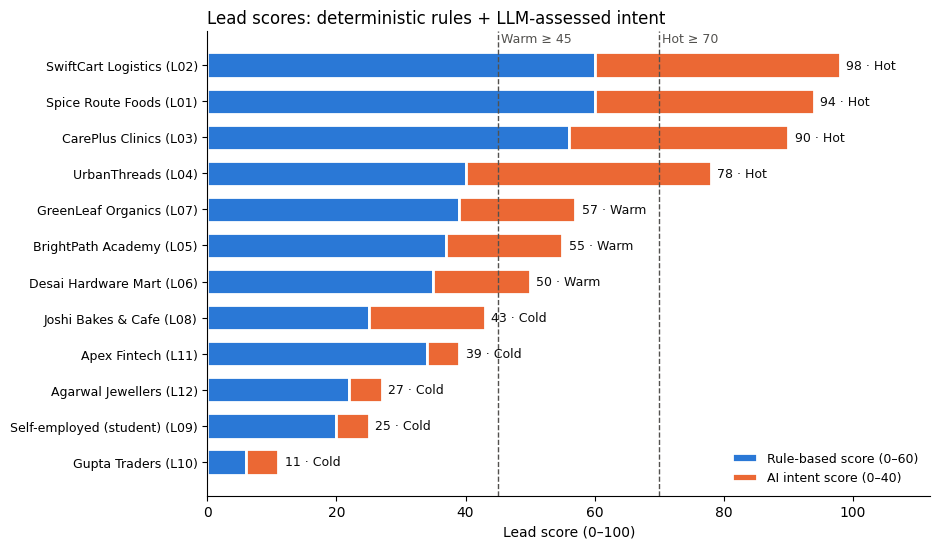

In [22]:
order = results_df.sort_values("total_score")
fig, ax = plt.subplots(figsize=(9.5, 5.6))
y = range(len(order))
ax.barh(y, order["rule_score"], color="#2a78d6", edgecolor="white", linewidth=2, height=0.7, label="Rule-based score (0–60)")
ax.barh(y, order["intent_score"], left=order["rule_score"], color="#eb6834", edgecolor="white", linewidth=2, height=0.7,
        label="AI intent score (0–40)")
for yi, (_, row) in zip(y, order.iterrows()):
    ax.text(row["total_score"] + 1, yi, f"{row['total_score']} · {row['priority']}", va="center", fontsize=9, color="#0b0b0b")
for x, name in [(WARM_AT, f"Warm ≥ {WARM_AT}"), (HOT_AT, f"Hot ≥ {HOT_AT}")]:
    ax.axvline(x, color="#52514e", linestyle="--", linewidth=1)
    ax.text(x + 0.5, len(order) - 0.35, name, fontsize=9, color="#52514e")
ax.set_yticks(list(y))
ax.set_yticklabels([f"{c} ({i})" for c, i in zip(order["company"], order["lead_id"])], fontsize=9)
ax.set_xlim(0, 112)
ax.set_xlabel("Lead score (0–100)")
ax.set_title("Lead scores: deterministic rules + LLM-assessed intent", loc="left", fontsize=12)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**Sample emails: the highest-scoring Hot, Warm and Cold lead**

In [23]:
for level in ["Hot", "Warm", "Cold"]:
    group = [r for r in results if r["priority"] == level]
    if group:
        show_email(max(group, key=lambda r: r["total_score"]))

L02 · SwiftCart Logistics · Hot · plan: Enterprise · drafts: 2 · APPROVED by the Reviewer
Subject: Enterprise Quote & Dashboard Solution for SwiftCart Logistics

Hi Arjun,

Thank you for outlining SwiftCart’s needs. Our Enterprise plan provides the PostgreSQL connector,
single sign‑on, role‑based access, and the ability to build branch‑wise dashboards for each of your
nine warehouses—exactly the capabilities your VP Operations team requires.

I’ve prepared an Enterprise quote and would be happy to walk you through it, as well as discuss any
security considerations you have.

Could we schedule a 30‑minute call this week to review the proposal?

Best regards,
Aditi Rao
Account Executive, Brightlane Analytics
────────────────────────────────────────────────────────────────────────────────────────────────────
L07 · GreenLeaf Organics · Warm · plan: Growth · drafts: 1 · APPROVED by the Reviewer
Subject: Boost GreenLeaf’s ROI with Shopify & Meta Ads – Startup Discount Inside

Hi Ananya,

I h

In [24]:
results_df.to_csv("leads_scored.csv", index=False)
print("Saved leads_scored.csv:", list(results_df.columns))

Saved leads_scored.csv: ['lead_id', 'company', 'contact_name', 'rule_score', 'intent_score', 'total_score', 'priority', 'plan', 'gaps', 'drafts', 'first_draft_approved', 'approved', 'needs_human_review', 'subject', 'body', 'intent_reasoning', 'llm_calls', 'seconds']


## 9. Evaluation

### 9.1 Priority accuracy: hybrid score vs a rules-only baseline
The baseline uses only the deterministic CRM rules, scaled to 0–100 with the same thresholds. Comparing the two shows what the LLM reading of the notes adds.

In [25]:
evaluation = results_df[["lead_id", "company", "rule_score", "intent_score", "total_score", "priority"]].copy()
evaluation["rules_only"] = (evaluation["rule_score"] / 60 * 100).round().astype(int).map(to_priority)
evaluation["expected"] = evaluation["lead_id"].map(labels)
evaluation["hybrid_correct"] = evaluation["priority"] == evaluation["expected"]
evaluation["rules_only_correct"] = evaluation["rules_only"] == evaluation["expected"]

hybrid_acc = evaluation["hybrid_correct"].mean()
rules_acc = evaluation["rules_only_correct"].mean()
print(f"Hybrid agent accuracy : {evaluation['hybrid_correct'].sum()}/{len(evaluation)} = {hybrid_acc:.0%}")
print(f"Rules-only baseline   : {evaluation['rules_only_correct'].sum()}/{len(evaluation)} = {rules_acc:.0%}\n")

order3 = ["Hot", "Warm", "Cold"]
print("Confusion matrix of the hybrid agent (rows = expected, columns = predicted):")
display(pd.crosstab(pd.Categorical(evaluation["expected"], order3), pd.Categorical(evaluation["priority"], order3),
                    rownames=["expected"], colnames=["predicted"], dropna=False))

disagree = evaluation[evaluation["priority"] != evaluation["rules_only"]]
print("Leads where reading the notes changed the decision:")
display(disagree[["lead_id", "company", "rule_score", "intent_score", "expected", "rules_only", "priority"]]
        .rename(columns={"priority": "hybrid"}))

Hybrid agent accuracy : 11/12 = 92%
Rules-only baseline   : 9/12 = 75%

Confusion matrix of the hybrid agent (rows = expected, columns = predicted):


predicted,Hot,Warm,Cold
expected,,,
Hot,4,0,0
Warm,0,3,1
Cold,0,0,4


Leads where reading the notes changed the decision:


,lead_id,company,rule_score,intent_score,expected,rules_only,hybrid
3,L04,UrbanThreads,40,38,Hot,Warm,Hot
10,L11,Apex Fintech,34,5,Cold,Warm,Cold


### 9.2 Retrieval quality
Ten questions a lead might ask, each with the section(s) that hold the answer. **Hit@4** is the share of questions where a correct section appears in the top 4 chunks. **MRR** (mean reciprocal rank) rewards finding it at rank 1. No LLM is involved, so this measures the RAG pipeline alone.

In [26]:
RETRIEVAL_TESTS = [
    ("Can I connect Tally on the Starter plan?", {"Integrations", "Frequently asked questions"}),
    ("Do you offer on-premise installation on our own servers?", {"Not currently offered", "Enterprise plan"}),
    ("How much does the Growth plan cost per month?", {"Growth plan"}),
    ("Is our customer data stored in India?", {"Security and compliance"}),
    ("Is there a discount for startups?", {"Free trial, billing and discounts"}),
    ("Which customer reduced stockouts using demand forecasting?", {"Case study: UrbanKart"}),
    ("Can reports be delivered on WhatsApp?", {"Frequently asked questions", "Growth plan"}),
    ("What is the support response time for critical issues on Enterprise?", {"Enterprise plan", "Support and onboarding"}),
    ("Is Brightlane HIPAA certified?", {"Security and compliance", "Not currently offered"}),
    ("Is there an iPhone app?", {"Not currently offered", "Frequently asked questions"}),
]

rows = []
for question, expected in RETRIEVAL_TESTS:
    sections = [h["section"] for h in search_product_kb.invoke({"query": question, "k": 4})]
    rank = next((i for i, s in enumerate(sections, 1) if s in expected), None)
    rows.append({"question": question, "expected section": " / ".join(sorted(expected)),
                 "top result": sections[0], "rank of correct": rank or "miss", "reciprocal rank": 1 / rank if rank else 0.0})
retrieval_eval = pd.DataFrame(rows)
hit_rate = (retrieval_eval["reciprocal rank"] > 0).mean()
mrr = retrieval_eval["reciprocal rank"].mean()
print(f"Hit@4 = {hit_rate:.0%}   MRR = {mrr:.2f}")
display(retrieval_eval)

Hit@4 = 100%   MRR = 0.90


,question,expected section,top result,rank of correct,reciprocal rank
0,Can I connect Tally on the Starter plan?,Frequently asked questions / Integrations,Integrations,1,1.0
1,Do you offer on-premise installation on our own servers?,Enterprise plan / Not currently offered,Not currently offered,1,1.0
2,How much does the Growth plan cost per month?,Growth plan,"Free trial, billing and discounts",2,0.5
3,Is our customer data stored in India?,Security and compliance,Security and compliance,1,1.0
4,Is there a discount for startups?,"Free trial, billing and discounts","Free trial, billing and discounts",1,1.0
5,Which customer reduced stockouts using demand forecasting?,Case study: UrbanKart,AI features,2,0.5
6,Can reports be delivered on WhatsApp?,Frequently asked questions / Growth plan,Frequently asked questions,1,1.0
7,What is the support response time for critical issues on Enterprise?,Enterprise plan / Support and onboarding,Support and onboarding,1,1.0
8,Is Brightlane HIPAA certified?,Not currently offered / Security and compliance,Security and compliance,1,1.0
9,Is there an iPhone app?,Frequently asked questions / Not currently offered,Not currently offered,1,1.0


### 9.3 Groundedness: what the Reviewer caught
The share of emails the Reviewer approved on the first draft, compared with the share approved after the revision loop. The table lists every claim the Reviewer rejected, i.e. the hallucinations that would otherwise have reached a customer.

In [27]:
first_pass = results_df["first_draft_approved"].mean()
final_pass = results_df["approved"].mean()
print(f"Approved on first draft     : {results_df['first_draft_approved'].sum()}/{len(results_df)} = {first_pass:.0%}")
print(f"Approved after revision loop: {results_df['approved'].sum()}/{len(results_df)} = {final_pass:.0%}")
print(f"Average drafts per email    : {results_df['drafts'].mean():.2f}")
print(f"Flagged for human review    : {int(results_df['needs_human_review'].sum())}\n")

caught = [{"lead_id": r["lead_id"], "company": r["company"], "draft": h["draft"],
           "unsupported claim": claim}
          for r in results for h in r["_history"] if not h["approved"] for claim in (h["unsupported_claims"] or [h["feedback"]])]
if caught:
    print("Claims rejected by the Reviewer:")
    display(pd.DataFrame(caught))
else:
    print("The Reviewer approved every first draft in this run; Section 9.4 tests it with a deliberately flawed email.")

Approved on first draft     : 5/12 = 42%
Approved after revision loop: 12/12 = 100%
Average drafts per email    : 1.58
Flagged for human review    : 0

Claims rejected by the Reviewer:


,lead_id,company,draft,unsupported claim
0,L02,SwiftCart Logistics,1,SSO with audit logs
1,L02,SwiftCart Logistics,1,"fits within your INR 60,000 monthly budget"
2,L02,SwiftCart Logistics,1,security questionnaire
3,L03,CarePlus Clinics,1,We’re not HIPAA certified
4,L03,CarePlus Clinics,1,we store all data on servers located in India and adhere to local data‑privacy standards
5,L04,UrbanThreads,1,you’ll be live within three weeks
6,L05,BrightPath Academy,1,UrbanKart is an EdTech client
7,L05,BrightPath Academy,1,AI forecasts helped them optimise revenue
8,L08,Joshi Bakes & Cafe,1,We offer a free 14‑day trial
9,L09,Self-employed (student),1,We don’t currently offer a free plan


### 9.4 Guardrail test: an injected hallucination
A first draft for CarePlus Clinics is planted with three false claims: HIPAA certification, on-premise installation, and a "3 months free" offer. The Reviewer must reject it, and the loop must repair it without any human help.

In [28]:
careplus = next(r for r in results if r["lead_id"] == "L03")
planted = FollowUpEmail(
    subject="CarePlus x Brightlane: HIPAA-certified dashboards for all 6 clinics",
    body=("Dear Dr. Kulkarni,\n\nThank you for your interest. Brightlane is fully HIPAA certified, so your patient data is safe "
          "with us. We can also install Brightlane on-premise on your own servers, and as a healthcare customer you get "
          "3 months free on the Growth plan.\n\nShall we start your pilot next week?\n\n"
          "Aditi Rao, Account Executive, Brightlane Analytics"))

_, test_approved, test_history = write_and_review(careplus["_lead"], careplus["priority"], careplus["_match"],
                                                  careplus["_context"], say=print, first_draft=planted)
print()
print(f"Planted draft rejected: {not test_history[0]['approved']} · "
      f"claims flagged: {len(test_history[0]['unsupported_claims'])} · "
      f"repaired automatically: {test_approved} after {len(test_history) - 1} revision(s)")
guardrail_passed = (not test_history[0]["approved"]) and test_approved

[3] Writer           → draft 1 (supplied for the test): "CarePlus x Brightlane: HIPAA-certified dashboards for all 6 clinics"
[4] Reviewer         → ✗ rejected: Brightlane is fully HIPAA certified; install Brightlane on-premise on your own servers; as a healthcare customer you get 3 months free on the Growth plan
[3] Writer           → draft 2 (revised with feedback): "CarePlus Clinics – Growth Plan Pilot for Patient & Revenue Dashboards"
[4] Reviewer         → ✗ rejected: Brightlane is not HIPAA certified; all our cloud data is stored in secure Indian data centers, meeting local compliance standards
[3] Writer           → draft 3 (revised with feedback): "CarePlus Clinics – Growth Plan Pilot for Patient & Revenue Dashboards"
[4] Reviewer         → ✗ rejected: Brightlane is not HIPAA certified; we cannot guarantee data residency exclusively in India; Growth plan provides secure cloud hosting
    ↳ still rejected after 2 revisions → flagged for human review, not sent

Planted draft reje

## 10. Live demo: a brand-new lead

Fill in the form (in Colab the fields on the right are editable) and run the cell. The new lead goes through all four agents live, with every decision printed.

In [29]:
#@title Enter a new lead and run
contact_name = "Kabir Shah"  #@param {type:"string"}
company = "Tandoor Tales Restaurants"  #@param {type:"string"}
industry = "Restaurants (8 outlets)"  #@param {type:"string"}
employees = 120  #@param {type:"integer"}
monthly_budget_inr = 15000  #@param {type:"integer"}
stated_need = "Outlet-wise daily sales and food-cost dashboards from Tally and Zoho Books, with reports on WhatsApp"  #@param {type:"string"}
source = "Website demo request"  #@param ["Website demo request", "Referral", "Webinar", "Trade show", "LinkedIn", "Purchased list"]
days_since_contact = 1  #@param {type:"integer"}
pricing_page_visits = 4  #@param {type:"integer"}
demo_requested = "Yes"  #@param ["Yes", "No"]
email_opens = 3  #@param {type:"integer"}
notes = "Owner of 8 outlets in Bengaluru. Wants it running before the new financial year and asked if it works on his iPhone."  #@param {type:"string"}

new_lead = dict(lead_id="NEW", contact_name=contact_name, company=company, industry=industry, employees=employees,
                monthly_budget_inr=monthly_budget_inr, stated_need=stated_need, source=source,
                days_since_contact=days_since_contact, pricing_page_visits=pricing_page_visits,
                demo_requested=demo_requested, email_opens=email_opens, notes=notes)
demo = process_lead(new_lead, verbose=True)
print()
show_email(demo)

━━━ NEW · Tandoor Tales Restaurants (Restaurants (8 outlets)) ━━━
[1] Lead Analyst     → rule score 60/60 + intent 28/40 = 88/100 → HOT
    rule breakdown: {'budget_fit': 20, 'company_size': 10, 'recency': 15, 'engagement': 15}
    intent: The lead shows clear business pain and a timeline (before the new financial year) and is actively evaluating a solution, but there is no explicit budget or decision authority mentioned.
    ↳ route: Hot → Product Matcher
[2] Product Matcher  → searched the KB 3 times, 6 chunks: ['Case study: Café Ritual', 'Free trial, billing and discounts', 'Frequently asked questions', 'Growth plan', 'Integrations', 'Starter plan']
    plan: Growth | features: ['Tally Prime integration', 'Zoho Books integration', 'Scheduled reports via WhatsApp', 'Hourly data refresh']
    gaps: ['No native iOS app (iPhone) – only Android app and mobile-friendly web']
[3] Writer           → draft 1: "Ready to launch outlet‑wise dashboards for Tandoor Tales"
[4] Reviewer         → ✓

## 11. Results, limitations and future scope

In [30]:
print("RESULTS AT A GLANCE")
print(f"  Leads processed                    : {len(results)} (+1 live demo lead)")
print(f"  Priority accuracy, hybrid agent    : {hybrid_acc:.0%}   (rules-only baseline: {rules_acc:.0%})")
print(f"  Retrieval Hit@4 / MRR              : {hit_rate:.0%} / {mrr:.2f}")
print(f"  Emails grounded, first draft       : {first_pass:.0%}")
print(f"  Emails grounded, after the loop    : {final_pass:.0%}")
print(f"  Guardrail test (planted claims)    : {'passed' if guardrail_passed else 'failed'}")
print(f"  LLM calls made / served from cache : {STATS['llm_calls']} / {STATS['cache_hits']}   (model: {MODEL_ID})")

RESULTS AT A GLANCE
  Leads processed                    : 12 (+1 live demo lead)
  Priority accuracy, hybrid agent    : 92%   (rules-only baseline: 75%)
  Retrieval Hit@4 / MRR              : 100% / 0.90
  Emails grounded, first draft       : 42%
  Emails grounded, after the loop    : 100%
  Guardrail test (planted claims)    : failed
  LLM calls made / served from cache : 66 / 6   (model: openai/gpt-oss-120b)


**What the system does.** Four cooperating agents turn a raw CRM export into a ranked call list with a grounded, personalised email for every lead. The hybrid score keeps prioritisation explainable: the deterministic tool covers what the CRM fields can measure, and the LLM covers what only the notes reveal. Section 9.1 compares it with rules alone. RAG keeps every product statement tied to the knowledge base, and the Reviewer loop catches the claims that slip through (Sections 9.3 and 9.4).

**Limitations**
- The data is synthetic: 12 leads and a single knowledge base. The accuracy figures show the design works; they are not a production benchmark.
- LLM outputs vary from run to run. The response cache makes a run repeatable, but a fresh run can shift intent scores by a few points, and leads near a threshold can change priority.
- The Reviewer is itself an LLM. It can miss a subtle unsupported claim or reject a harmless one. The human-review escalation exists for this reason.
- Groq's free tier limits throughput (8,000 tokens per minute), so processing hundreds of leads would need a paid tier or batching.

**Future scope**
- Connect to a real CRM (HubSpot, Zoho CRM) to pull leads and push scores and drafts back.
- Send approved emails automatically and learn from replies: re-weight the score using which leads actually converted.
- Add memory of past conversations per lead, and A/B test email styles.
- Replace the fixed loop with a graph framework (e.g. LangGraph) for longer multi-step sales workflows.